In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.utils import image_dataset_from_directory
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:

import os
import zipfile

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the dataset ZIP file first.")

zip_path = zip_files[0]
extract_dir = "/content/alzheimer_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")
print("Main folder contents:", os.listdir(extract_dir))


Dataset extracted successfully!
Main folder contents: ['Data']


In [13]:

class_names_expected = {
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented"
}

data_dir = None

for root, dirs, files in os.walk(extract_dir):
    if class_names_expected.issubset(set(dirs)):
        data_dir = root
        break

if data_dir is None:
    print("Could not find all four class folders.")
    for root, dirs, files in os.walk(extract_dir):
        print(root, dirs[:10])
else:
    print("Image dataset folder:", data_dir)
    print("Classes:", os.listdir(data_dir))


Image dataset folder: /content/alzheimer_data/Data
Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']


In [14]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

train_ds = train_ds.map(
    lambda x, y: (x / 255.0, y)
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (x / 255.0, y)
).prefetch(tf.data.AUTOTUNE)

print("Classes:", class_names)
print("Number of classes:", num_classes)


Found 40000 files belonging to 4 classes.
Using 32000 files for training.
Found 40000 files belonging to 4 classes.
Using 8000 files for validation.
Classes: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Number of classes: 4


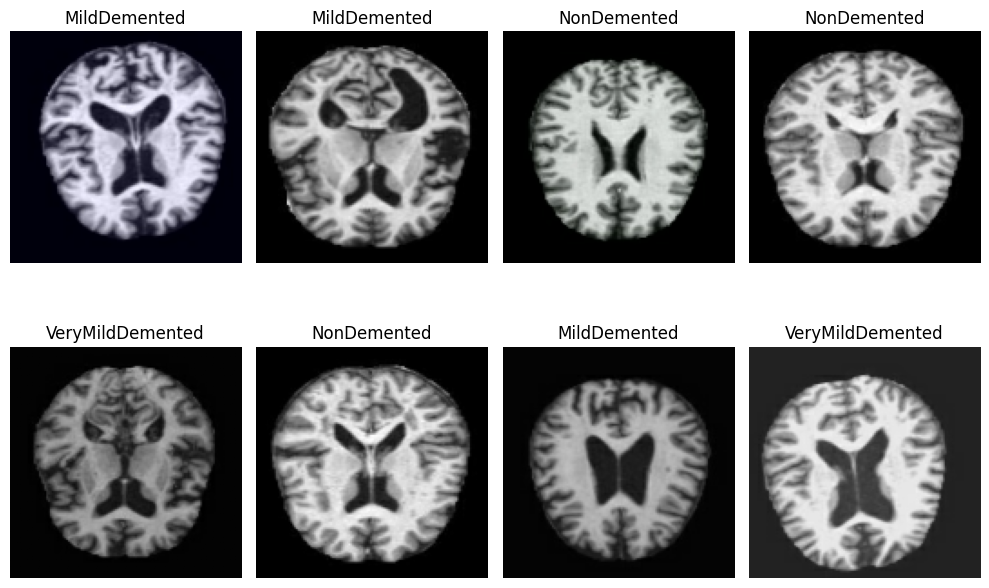

In [15]:

images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 7))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [16]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_alzheimer_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)


Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 34s 26ms/step - accuracy: 0.5895 - loss: 0.8775 - val_accuracy: 0.7318 - val_loss: 0.6053
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 25s 25ms/step - accuracy: 0.7436 - loss: 0.5629 - val_accuracy: 0.8194 - val_loss: 0.4201
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 24s 24ms/step - accuracy: 0.8140 - loss: 0.4243 - val_accuracy: 0.8545 - val_loss: 0.3432
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 24s 24ms/step - accuracy: 0.8540 - loss: 0.3368 - val_accuracy: 0.8876 - val_loss: 0.2824
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 24ms/step - accuracy: 0.8786 - loss: 0.2799 - val_accuracy: 0.8906 - val_loss: 0.2782


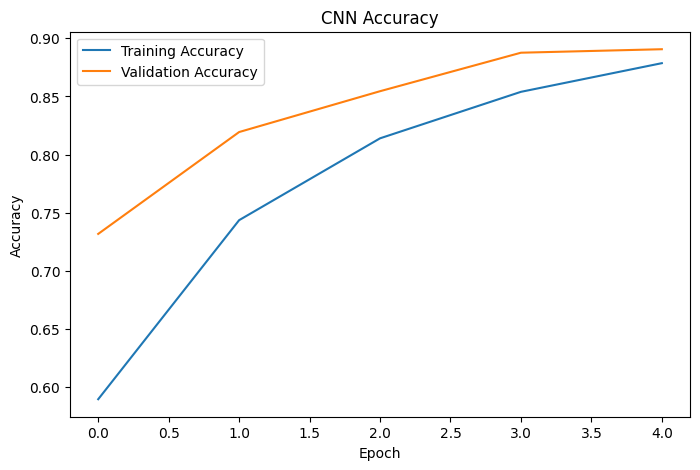

In [18]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()


In [ ]:

model.save("/content/alzheimer_cnn_final.keras")
print("CNN model saved successfully!")


CNN model saved successfully!


In [19]:

print("TensorFlow available:", "tf" in globals())
print("Dataset available:", "train_ds" in globals())
print("Model available:", "model" in globals())
print("Training history available:", "history" in globals())

TensorFlow available: True
Dataset available: True
Model available: True
Training history available: True


In [20]:
import os
import tensorflow as tf

model_path = "/content/alzheimer_cnn_final.keras"

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path)
    print("CNN model loaded successfully!")
    model.summary()
else:
    print("Model file not found in the current Colab session.")

Model file not found in the current Colab session.


In [2]:

import os

from google.colab import drive
drive.mount('/content/drive')

possible_paths = [
    "/content/drive/MyDrive/Alzheimer_Project_Results/alzheimer_cnn_final.keras",
    "/content/drive/MyDrive/alzheimer_cnn_final.keras",
    "/content/drive/MyDrive/Alzheimer_Project_Results/best_alzheimer_cnn.keras"
]

for path in possible_paths:
    if os.path.exists(path):
        print("FOUND:", path)


Mounted at /content/drive


In [3]:

import os

search_roots = ["/content/drive/MyDrive"]

model_files = []

for root in search_roots:
    for current_path, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".Trash", ".ipynb_checkpoints"]]
        for file in files:
            if file.endswith((".keras", ".h5")):
                model_files.append(os.path.join(current_path, file))

if model_files:
    print("Saved model files found:")
    for path in model_files:
        print(path)
else:
    print("No saved .keras or .h5 model found in Google Drive.")


No saved .keras or .h5 model found in Google Drive.


In [4]:

import os

for path in [
    "/content/alzheimer_data",
    "/content/drive/MyDrive"
]:
    print("\nPath:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:", os.listdir(path)[:15])



Path: /content/alzheimer_data
Exists: False

Path: /content/drive/MyDrive
Exists: True
Contents: ['suh24cse0236-500 to 1000 difficulty rating (1).pdf', 'suh24cse0236-Sreenidhi University __ 24CSEL205_ Programming through Python (1).pdf', 'SPANDANA PYTHON.01.docx', 'spandana[1][1].docx', 'CSE_ds_through_cpp_final[1][1].docx', 'CSE_ds_through_cpp_final[1][1].pdf', 'CSE_ds_through_cpp_final-1--1-.docx.pdf', '20250709_100042AMByGPSMapCamera.jpg', '20250709_100045AMByGPSMapCamera.jpg', '20250709_113210AMByGPSMapCamera.jpg', 'InShot_20250709_194404356.mp4', '20250710_103647AMByGPSMapCamera.jpg', '20250715_110632AMByGPSMapCamera.jpg', '20250716_110631AMByGPSMapCamera.jpg', '20250716_110629AMByGPSMapCamera.jpg']


In [5]:

import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in [".Trash", ".ipynb_checkpoints"]]

    for file in files:
        name = file.lower()
        if (
            "alzheimer" in name
            or name.endswith((".keras", ".h5"))
            or (name.endswith(".zip") and ("mri" in name or "dataset" in name))
        ):
            matches.append(os.path.join(root, file))

if matches:
    print("Possible project files:")
    for path in matches:
        print(path)
else:
    print("No matching Alzheimer dataset or saved model found.")


Possible project files:
/content/drive/MyDrive/Alzheimers_Disease_Abstract.docx
/content/drive/MyDrive/Colab Notebooks/Alzheimers_CNN_Project.ipynb..ipynb


In [6]:

import os

notebook_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Alzheimers_CNN_Project.ipynb..ipynb"
)

print("Notebook exists:", os.path.exists(notebook_path))


Notebook exists: True


In [7]:

import json

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if source.strip():
            print(f"\n--- Code Cell {i + 1} ---")
            print(source[:700])



--- Code Cell 1 ---

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.utils import image_dataset_from_directory
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


--- Code Cell 2 ---

from google.colab import files

uploaded = files.upload()


--- Code Cell 3 ---

import os
import zipfile

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the dataset ZIP file first.")

zip_path = zip_files[0]
extract_dir = "/content/alzheimer_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")
print("Main folder contents:", os.listdir(extract_dir))


--- Code Cell 4 ---

class_names_expected

In [21]:

loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")


250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.8906 - loss: 0.2782
Validation Loss: 0.2782
Validation Accuracy: 89.06%


In [22]:

import numpy as np

y_true = np.concatenate([labels.numpy() for images, labels in val_ds])

y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)
print("Number of classes:", len(class_names))


250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step
Actual labels shape: (8000,)
Predicted labels shape: (8000,)
Number of classes: 4


In [23]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


                  precision    recall  f1-score   support

    MildDemented       0.24      0.24      0.24      1994
ModerateDemented       0.25      0.25      0.25      2034
     NonDemented       0.25      0.22      0.23      2052
VeryMildDemented       0.23      0.26      0.24      1920

        accuracy                           0.24      8000
       macro avg       0.24      0.24      0.24      8000
    weighted avg       0.24      0.24      0.24      8000



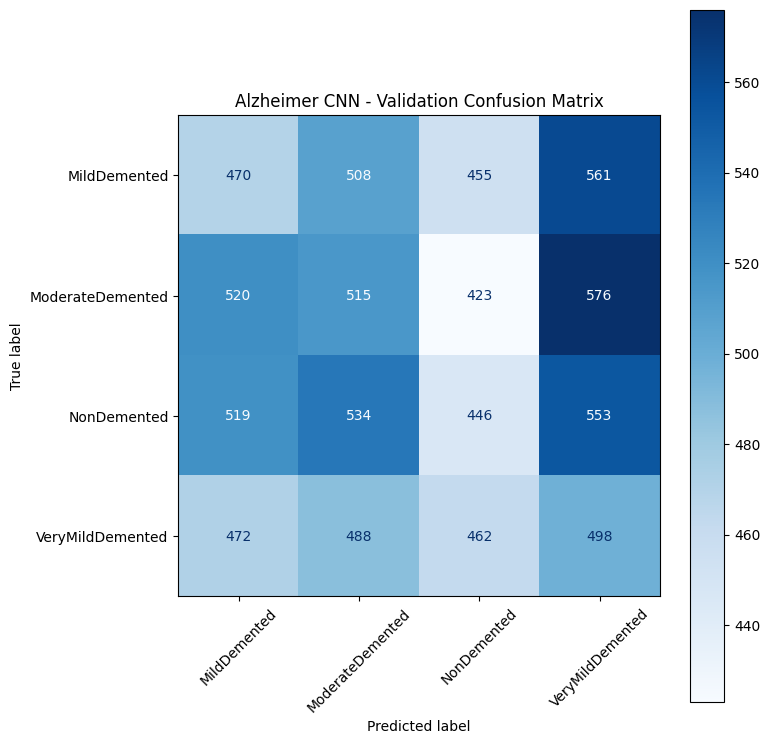

In [24]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Alzheimer CNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [25]:

import os
import json
import numpy as np

results_dir = "/content/drive/MyDrive/Alzheimer_Project_Results"
os.makedirs(results_dir, exist_ok=True)

model.save(os.path.join(results_dir, "alzheimer_cnn_final.keras"))

np.savetxt(
    os.path.join(results_dir, "confusion_matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d"
)

with open(os.path.join(results_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=2)

print("Model and evaluation results saved to Google Drive.")


Model and evaluation results saved to Google Drive.


In [26]:

import os

results_dir = "/content/drive/MyDrive/Alzheimer_Project_Results"

print("Results folder exists:", os.path.exists(results_dir))

if os.path.exists(results_dir):
    for file in os.listdir(results_dir):
        print("✓", file)


Results folder exists: True
✓ alzheimer_cnn_final.keras
✓ confusion_matrix.csv
✓ class_names.json


In [27]:

from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

report_path = os.path.join(results_dir, "classification_report.txt")

with open(report_path, "w") as f:
    f.write(report)

print(report)
print("\nClassification report saved!")


                  precision    recall  f1-score   support

    MildDemented       0.24      0.24      0.24      1994
ModerateDemented       0.25      0.25      0.25      2034
     NonDemented       0.25      0.22      0.23      2052
VeryMildDemented       0.23      0.26      0.24      1920

        accuracy                           0.24      8000
       macro avg       0.24      0.24      0.24      8000
    weighted avg       0.24      0.24      0.24      8000


Classification report saved!


In [29]:

import os
import json

results_dir = "/content/drive/MyDrive/Alzheimer_Project_Results"
os.makedirs(results_dir, exist_ok=True)

if "history" in globals():
    history_path = os.path.join(results_dir, "training_history.json")

    with open(history_path, "w") as f:
        json.dump(history.history, f, indent=2)

    print("Training history saved!")
else:
    print("Training history is unavailable; no history file saved.")


Training history saved!


In [30]:

import os

report_path = (
    "/content/drive/MyDrive/Alzheimer_Project_Results/"
    "classification_report.txt"
)

if os.path.exists(report_path):
    with open(report_path, "r") as f:
        print(f.read())
else:
    print("Classification report file not found.")


                  precision    recall  f1-score   support

    MildDemented       0.24      0.24      0.24      1994
ModerateDemented       0.25      0.25      0.25      2034
     NonDemented       0.25      0.22      0.23      2052
VeryMildDemented       0.23      0.26      0.24      1920

        accuracy                           0.24      8000
       macro avg       0.24      0.24      0.24      8000
    weighted avg       0.24      0.24      0.24      8000



In [31]:

import os
import json

results_dir = "/content/drive/MyDrive/Alzheimer_Project_Results"
os.makedirs(results_dir, exist_ok=True)

if "history" in globals():
    with open(os.path.join(results_dir, "training_history.json"), "w") as f:
        json.dump(history.history, f, indent=2)
    print("Training history saved successfully!")
else:
    print("Training history is unavailable.")


Training history saved successfully!
